In [1]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score

# Ensure project root is on sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.autoencoder import FraudAutoencoder, train_autoencoder, set_deterministic_seed
from src.unsupervised_metrics import generate_unsupervised_pseudo_labels

set_deterministic_seed(42)
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print(f"Compute Device: {DEVICE}")

FEATURE_COLS = [f"V{i}" for i in range(1, 29)] + ["Amount"]

# Load Full vs Deduplicated legitimate training sets + Val/Test splits
train_full_df = pd.read_csv(PROJECT_ROOT / "data/processed/train_legit.csv")
train_dedup_df = pd.read_csv(PROJECT_ROOT / "data/processed/train_legit_dedup.csv")
val_df = pd.read_csv(PROJECT_ROOT / "data/processed/val.csv")
test_df = pd.read_csv(PROJECT_ROOT / "data/processed/test.csv")

print(f"Train Legit (Full)        : {len(train_full_df):>7,} rows")
print(f"Train Legit (Deduplicated): {len(train_dedup_df):>7,} rows (Removed {len(train_full_df) - len(train_dedup_df):,} exact duplicates)")
print(f"Validation Split          : {len(val_df):>7,} rows ({int(val_df['Class'].sum())} frauds)")
print(f"Held-Out Test Split       : {len(test_df):>7,} rows ({int(test_df['Class'].sum())} frauds)")

# Fit StandardScaler strictly on deduplicated legitimate training data
scaler_dedup = StandardScaler()
X_train = scaler_dedup.fit_transform(train_dedup_df[FEATURE_COLS].values)

X_val = scaler_dedup.transform(val_df[FEATURE_COLS].values)
y_val = val_df["Class"].values
X_val_legit = X_val[y_val == 0]

X_test = scaler_dedup.transform(test_df[FEATURE_COLS].values)
y_test = test_df["Class"].values

Compute Device: mps
Train Legit (Full)        : 170,524 rows
Train Legit (Deduplicated): 165,279 rows (Removed 5,245 exact duplicates)
Validation Split          :  56,961 rows (57 frauds)
Held-Out Test Split       :  56,962 rows (75 frauds)


In [2]:
# Compare identical Autoencoder (latent_dim=8) trained on Full (with duplicates) vs Deduplicated
scaler_full = StandardScaler()
X_train_full = scaler_full.fit_transform(train_full_df[FEATURE_COLS].values)
X_val_full = scaler_full.transform(val_df[FEATURE_COLS].values)
X_val_full_legit = X_val_full[y_val == 0]

ablation_rows = []
for label, X_tr, X_v, X_v_leg in [
    ("With Duplicates (170,524 rows)", X_train_full, X_val_full, X_val_full_legit),
    ("Deduplicated (165,279 rows)",    X_train,      X_val,      X_val_legit),
]:
    ae_ablate = FraudAutoencoder(input_dim=29, hidden_dims=(22, 14), latent_dim=8, dropout_rate=0.10)
    ae_ablate, _ = train_autoencoder(
        model=ae_ablate, X_train=X_tr, X_val_legit=X_v_leg,
        epochs=35, batch_size=512, lr=1e-3, weight_decay=1e-4,
        noise_std=0.0, patience=6, device=DEVICE, seed=42
    )
    tr_mse = ae_ablate.reconstruction_errors(X_tr, device=DEVICE)
    val_mse = ae_ablate.reconstruction_errors(X_v, device=DEVICE)
    ablation_rows.append({
        "Training Partition": label,
        "Train Legit MSE": round(float(np.mean(tr_mse)), 4),
        "Val Legit MSE": round(float(np.mean(val_mse[y_val == 0])), 4),
        "Val 99% Cutoff": round(float(np.quantile(tr_mse, 0.99)), 4),
        "Val PR-AUC": round(float(average_precision_score(y_val, val_mse)), 4),
        "Val ROC-AUC": round(float(roc_auc_score(y_val, val_mse)), 4),
    })

ablation_df = pd.DataFrame(ablation_rows)
print("\n=== TABLE 1: DUPLICATE REMOVAL ABLATION (AUTOENCODER LATENT=8) ===")
print(ablation_df.to_string(index=False))


=== TABLE 1: DUPLICATE REMOVAL ABLATION (AUTOENCODER LATENT=8) ===
            Training Partition  Train Legit MSE  Val Legit MSE  Val 99% Cutoff  Val PR-AUC  Val ROC-AUC
With Duplicates (170,524 rows)           0.3471         0.5953          1.7199      0.0745       0.9445
   Deduplicated (165,279 rows)           0.3506         0.5929          1.7452      0.0683       0.9449


In [4]:
sweep_configs = [
    {"name": "AE (latent=4)",              "latent_dim": 4,  "noise_std": 0.00, "dropout": 0.10},
    {"name": "AE (latent=8)",              "latent_dim": 8,  "noise_std": 0.00, "dropout": 0.10},
    {"name": "AE (latent=12)",             "latent_dim": 12, "noise_std": 0.00, "dropout": 0.10},
    {"name": "AE (latent=16)",             "latent_dim": 16, "noise_std": 0.00, "dropout": 0.10},
    {"name": "DAE (latent=8, noise=0.05)", "latent_dim": 8,  "noise_std": 0.05, "dropout": 0.10},
    {"name": "DAE (latent=12, noise=0.05)","latent_dim": 12, "noise_std": 0.05, "dropout": 0.10},
]

sweep_results = []
trained_models = {}
histories = {}

for cfg in sweep_configs:
    print(f"Training {cfg['name']} ...")
    model = FraudAutoencoder(
        input_dim=29,
        hidden_dims=(22, 14),
        latent_dim=cfg["latent_dim"],
        dropout_rate=cfg["dropout"],
    )
    model, hist = train_autoencoder(
        model=model,
        X_train=X_train,
        X_val_legit=X_val_legit,
        epochs=35,
        batch_size=512,
        lr=1e-3,
        weight_decay=1e-4,
        noise_std=cfg["noise_std"],
        patience=6,
        device=DEVICE,
        seed=42,
    )

    train_mse = model.reconstruction_errors(X_train, device=DEVICE)
    val_mse = model.reconstruction_errors(X_val, device=DEVICE)

    val_legit_mse = float(np.mean(val_mse[y_val == 0]))
    pseudo_res = generate_unsupervised_pseudo_labels(train_mse, val_mse, quantile=0.99)

    val_pr_auc = float(average_precision_score(y_val, val_mse))
    val_roc_auc = float(roc_auc_score(y_val, val_mse))
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    sweep_results.append({
        "Architecture": cfg["name"],
        "Latent Dim": cfg["latent_dim"],
        "Noise Std": cfg["noise_std"],
        "Params": n_params,
        "Train MSE (Unsup)": round(float(np.mean(train_mse)), 4),
        "Val Legit MSE (Unsup)": round(val_legit_mse, 4),
        "Val 99% Cutoff (Unsup)": round(pseudo_res["cutoff"], 4),
        "Val PR-AUC": round(val_pr_auc, 4),
        "Val ROC-AUC": round(val_roc_auc, 4),
    })
    trained_models[cfg["name"]] = model
    histories[cfg["name"]] = hist

sweep_df = pd.DataFrame(sweep_results)
print("\n=== TABLE 2: AUTOENCODER BOTTLENECK & DENOISING SWEEP (VALIDATION SET) ===")
print(sweep_df.to_string(index=False))

Training AE (latent=4) ...
Training AE (latent=8) ...
Training AE (latent=12) ...
Training AE (latent=16) ...
Training DAE (latent=8, noise=0.05) ...
Training DAE (latent=12, noise=0.05) ...

=== TABLE 2: AUTOENCODER BOTTLENECK & DENOISING SWEEP (VALIDATION SET) ===
               Architecture  Latent Dim  Noise Std  Params  Train MSE (Unsup)  Val Legit MSE (Unsup)  Val 99% Cutoff (Unsup)  Val PR-AUC  Val ROC-AUC
              AE (latent=4)           4       0.00    2253             0.4907                 0.7418                  2.3849      0.0478       0.9357
              AE (latent=8)           8       0.00    2369             0.3506                 0.5929                  1.7452      0.0683       0.9449
             AE (latent=12)          12       0.00    2485             0.2967                 0.4860                  1.4322      0.1222       0.9467
             AE (latent=16)          16       0.00    2601             0.2884                 0.5121                  1.5165      0.0

Selected Best Architecture: AE (latent=12) | Val PR-AUC = 0.1222 | Val ROC-AUC = 0.9467
Saved: models/scaler_dedup.joblib and models/best_autoencoder.pt


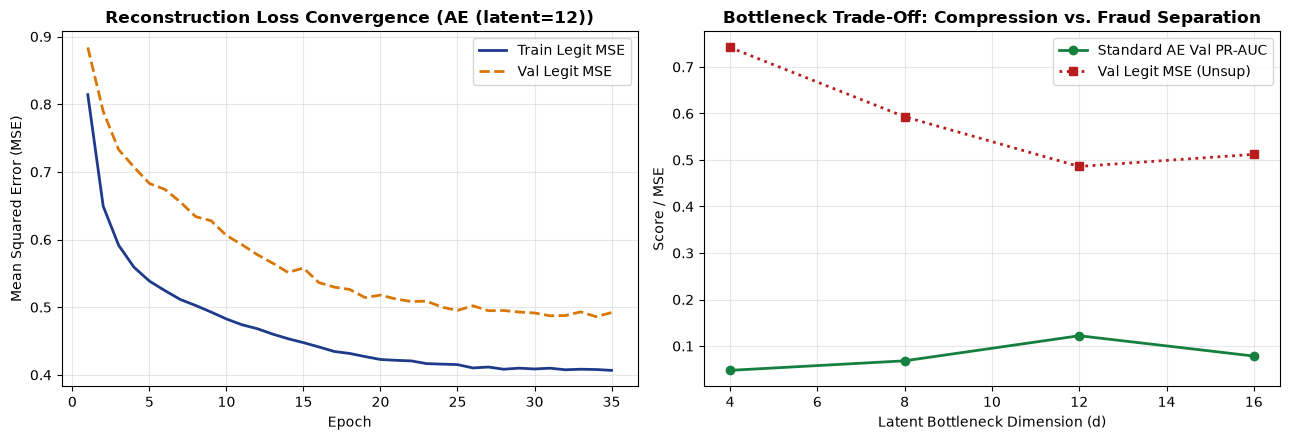

In [5]:
best_row = sweep_df.sort_values("Val PR-AUC", ascending=False).iloc[0]
best_name = best_row["Architecture"]
best_model = trained_models[best_name]
best_history = histories[best_name]

print(f"Selected Best Architecture: {best_name} | Val PR-AUC = {best_row['Val PR-AUC']:.4f} | Val ROC-AUC = {best_row['Val ROC-AUC']:.4f}")

# Serialize scaler and PyTorch state_dict
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(scaler_dedup, models_dir / "scaler_dedup.joblib")
torch.save(
    {
        "architecture": best_name,
        "latent_dim": int(best_row["Latent Dim"]),
        "hidden_dims": (22, 14),
        "dropout_rate": 0.10,
        "state_dict": best_model.cpu().state_dict(),
    },
    models_dir / "best_autoencoder.pt",
)
best_model = best_model.to(DEVICE)
print("Saved: models/scaler_dedup.joblib and models/best_autoencoder.pt")

# Plot convergence and bottleneck sweep
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

epochs_ran = range(1, len(best_history["train_loss"]) + 1)
axes[0].plot(epochs_ran, best_history["train_loss"], label="Train Legit MSE", lw=2, color="#1e3a8a")
axes[0].plot(epochs_ran, best_history["val_loss"], label="Val Legit MSE", lw=2, linestyle="--", color="#d97706")
axes[0].set_title(f"Reconstruction Loss Convergence ({best_name})", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error (MSE)")
axes[0].legend()
axes[0].grid(alpha=0.3)

ae_only = sweep_df[sweep_df["Noise Std"] == 0.0]
axes[1].plot(ae_only["Latent Dim"], ae_only["Val PR-AUC"], marker="o", lw=2, color="#15803d", label="Standard AE Val PR-AUC")
axes[1].plot(ae_only["Latent Dim"], ae_only["Val Legit MSE (Unsup)"], marker="s", lw=2, color="#b91c1c", linestyle=":", label="Val Legit MSE (Unsup)")
axes[1].set_title("Bottleneck Trade-Off: Compression vs. Fraud Separation", fontweight="bold")
axes[1].set_xlabel("Latent Bottleneck Dimension (d)")
axes[1].set_ylabel("Score / MSE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

=== TABLE 3: TOP 10 FEATURES DRIVING AUTOENCODER RECONSTRUCTION ERROR ON FRAUD ===
Feature  Legit Mean Sq Error  Fraud Mean Sq Error  Fraud/Legit Error Ratio
    V14               0.3164            38.999901               123.279999
    V17               0.2494            34.250599               137.339996
    V12               0.2763            16.521799                59.790001
    V10               0.2267            16.419001                72.419998
    V16               0.3648            15.453600                42.360001
     V3               1.2007             9.860100                 8.210000
     V4               0.3461             7.255300                20.969999
     V7               0.3577             6.427200                17.969999
    V11               0.6946             5.646300                 8.130000
     V9               0.3259             5.435900                16.680000


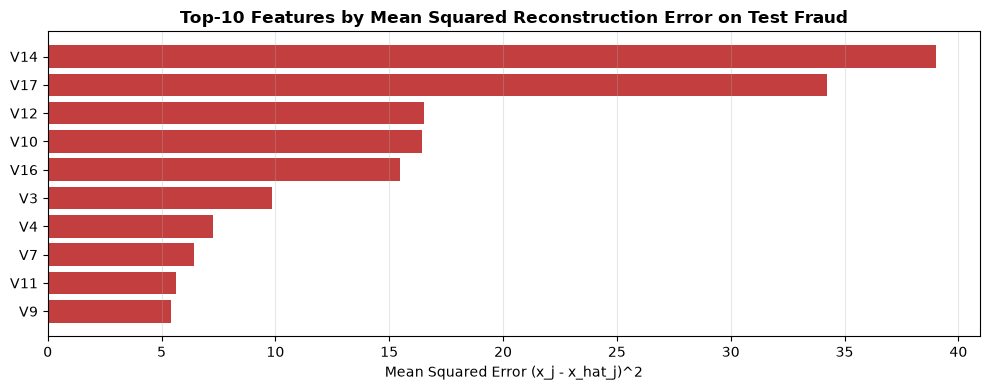

In [6]:
test_feat_err = best_model.feature_squared_errors(X_test, device=DEVICE)
fraud_mean_err = np.mean(test_feat_err[y_test == 1], axis=0)
legit_mean_err = np.mean(test_feat_err[y_test == 0], axis=0)
err_ratio = fraud_mean_err / (legit_mean_err + 1e-8)

attr_df = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Legit Mean Sq Error": np.round(legit_mean_err, 4),
    "Fraud Mean Sq Error": np.round(fraud_mean_err, 4),
    "Fraud/Legit Error Ratio": np.round(err_ratio, 2),
}).sort_values("Fraud Mean Sq Error", ascending=False)

print("=== TABLE 3: TOP 10 FEATURES DRIVING AUTOENCODER RECONSTRUCTION ERROR ON FRAUD ===")
print(attr_df.head(10).to_string(index=False))

plt.figure(figsize=(10, 4))
top10 = attr_df.head(10).iloc[::-1]
plt.barh(top10["Feature"], top10["Fraud Mean Sq Error"], color="#b91c1c", alpha=0.85)
plt.title("Top-10 Features by Mean Squared Reconstruction Error on Test Fraud", fontweight="bold")
plt.xlabel("Mean Squared Error (x_j - x_hat_j)^2")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()